### College of Computing and Informatics, Drexel University
### DSCI 521: Data Analysis and Interpretation
---

## Final Project Report

## Project Title: Understanding and Predicting Employee Turnover at Tech Companies

## Student(s): Mary Sullivan (mes529@drexel.edu)

## Date: 5/20/2025
---

## Your project should include the following components:
- Problem Definition: Define a clear problem or task to solve using data analysis techniques.

- Dataset Selection: You must choose a dataset relevant to your interests or a specific domain. The dataset should be of sufficient size and complexity to demonstrate various data analysis techniques.

- Exploratory Data Analysis (EDA): You need to perform thorough EDA on the dataset to understand its characteristics, identify patterns, missing values, outliers, and potential features for modeling.

- Feature Engineering: Implement feature engineering for creating new features, transforming existing ones, or selecting relevant features.

- Model Evaluation and Selection: Experiment with different data analysis algorithms and techniques. Evaluate the models using appropriate evaluation metrics

- Conclusion: Discuss your findings and future work.

## You should write the report with following characristics to ensure effective communication:
- Visualization and Interpretation: You should use visulization throughout EDA, modeling, and evaluation to illustrate any insights.

- Code and Implementation: Throughout the notebook, you must write well-structured and commented code.

- Documentation and Presentation: Throughout the notebook, you must add comprehensive commentary text to explain plots and code snippets. Always provide interpretations and explanations to document your analyses and results.

### 1. Problem Definition
---
*(Define the problem that will be solved in this data analytics project.)*

In [1]:
print("High employee turnover is costly for companies. By identifying risk factors and predicting turnover, HR teams can take proactive measures to improve retention and avoid hiring employees with certain risks.")
print("The goal of this project is to predict whether an employee will leave based on demographic, job satisfaction, and performance-related features. This is a binary (yes/no) classification problem.")

High employee turnover is costly for companies. By identifying risk factors and predicting turnover, HR teams can take proactive measures to improve retention and avoid hiring employees with certain risks.
The goal of this project is to predict whether an employee will leave based on demographic, job satisfaction, and performance-related features. This is a binary (yes/no) classification problem.


### 2. Data Sets
---
*(Describe the origin of the data sources. What is the format of the original data? How to access the data?)*

In [10]:
print("This is a fictional dataset of IBM eployees created by IBM Data Scientists. It contains employee data with fields for demographic, job satisfaction, distance from work, department, etc.\nIt also has a boolean field \"Attrition\" which indicates the employees departure. I will use this to determine what key factors can be used to predict a future departure.")
print("The data is available via the Kaggle API and can be accessed through the kagglehub module. The following code downloads the file as a csv and saves the path.")

import kagglehub

# Download latest version through Kaggle
path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")

print("Path to dataset files:", path)

This is a fictional dataset of IBM eployees created by IBM Data Scientists. It contains employee data with fields for demographic, job satisfaction, distance from work, department, etc.
It also has a boolean field "Attrition" which indicates the employees departure. I will use this to determine what key factors can be used to predict a future departure.
The data is available via the Kaggle API and can be accessed through the kagglehub module. The following code downloads the file as a csv and saves the path.
Path to dataset files: /Users/mary/.cache/kagglehub/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/versions/1


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [25]:
# load in data
df = pd.read_csv(path + '/WA_Fn-UseC_-HR-Employee-Attrition.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### 3. Exploration and Feature Engineering
---
*(Describe and present any code and methods used for exploring and visualizing the data, including statistical analysis and examination of correlations between features. Perform feature engineering to support model development.)*

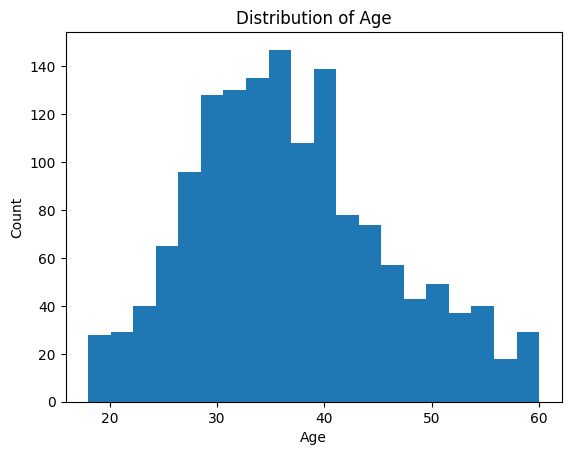

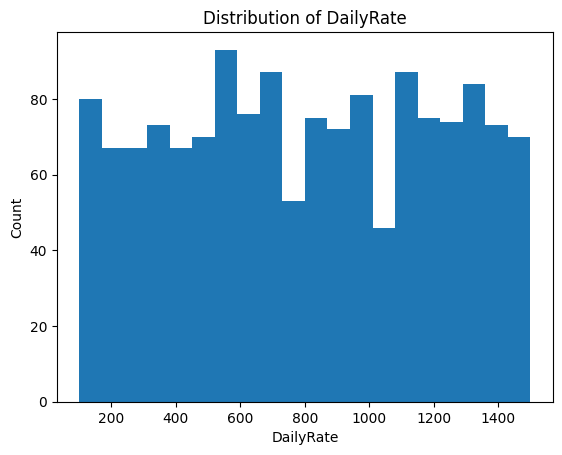

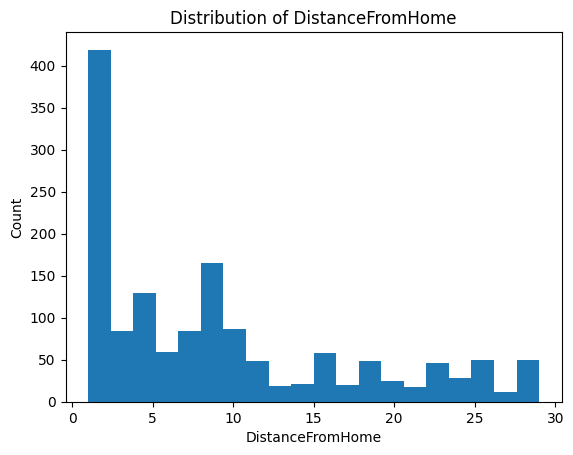

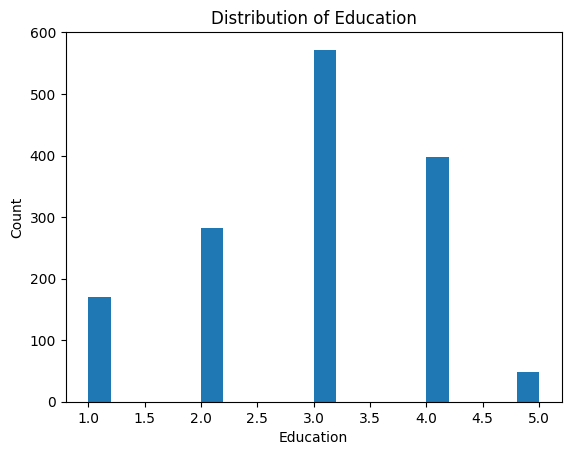

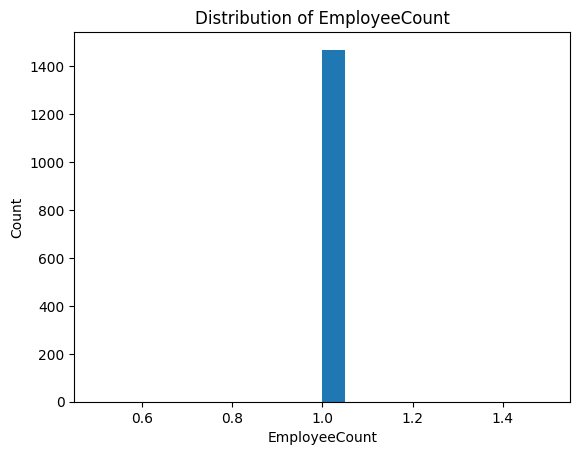

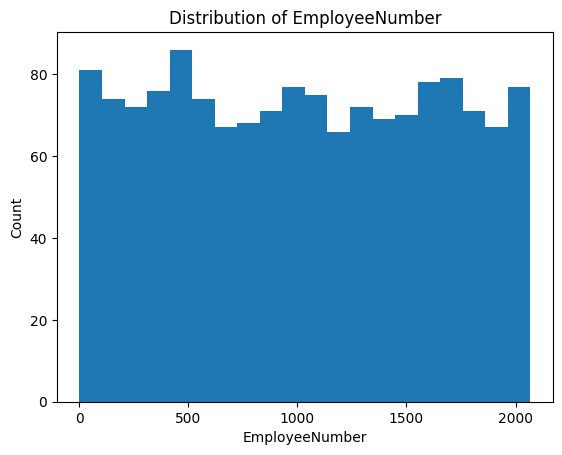

In [7]:
#### EXPLORATION ####
# histograms of numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
for col in numeric_cols[:6]:  # show a subset to keep it quick
    plt.figure()
    df[col].dropna().plot(kind='hist', bins=20, title=f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.show()

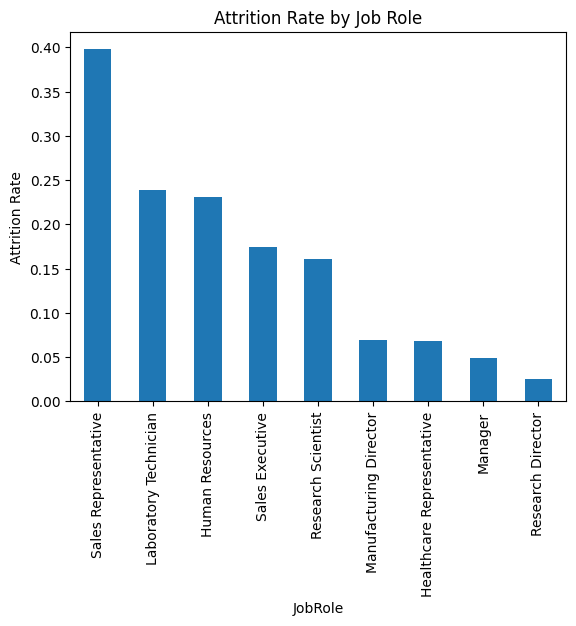

In [9]:
# Attrition by JobRole
rates = df.groupby('JobRole')['Attrition'].apply(lambda s: (s=='Yes').mean()).sort_values(ascending=False)
plt.figure()
rates.plot(kind='bar', title=f'Attrition Rate by Job Role')
plt.ylabel('Attrition Rate')
plt.show()

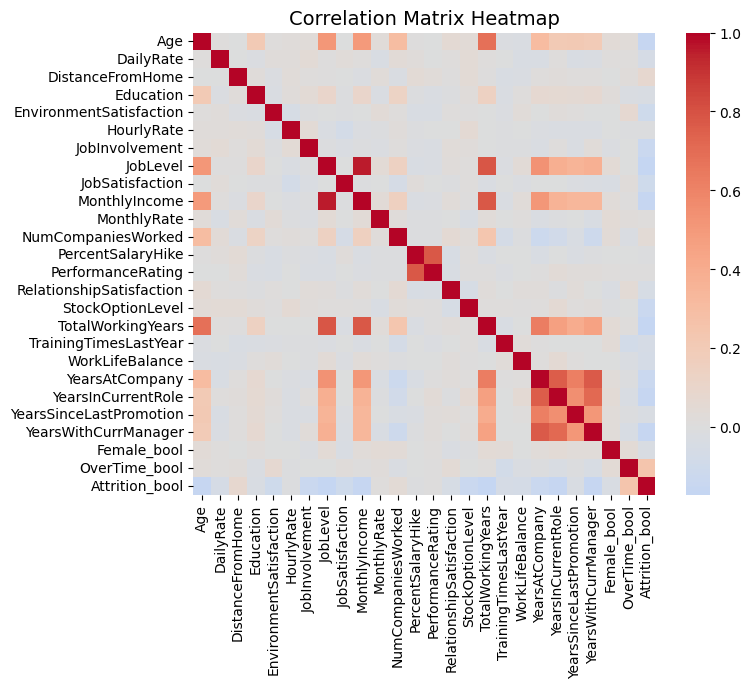

In [18]:
#### FEATURE ENGINEERING ####
# convert bool columns to bool
df['Attrition_bool'] = df['Attrition'].apply(lambda s: (s=='Yes'))
df['Female_bool'] = df['Gender'].apply(lambda s: (s=='Female'))
df['OverTime_bool'] = df['OverTime'].apply(lambda s: (s=='Yes'))


# correlation matrix
cols_to_comp = ['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Female_bool',
 'OverTime_bool',
 'Attrition_bool']

corr = df[cols_to_comp].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix Heatmap", fontsize=14)
plt.show()


In [19]:
print("The correlation matrix helps to vizualize which numerical features might be able to predict attrition.\nThe variables with highest correlation are OverTime, NumCompaniesWorked and DistanceFromHome, which aligns with expectations")

The correlation matrix helps to vizualize which features might be able to predict attrition.
The variables with highest correlation are OverTime, NumCompaniesWorked and DistanceFromHome, which aligns with expectations


In [27]:
df_model = df.copy()
df_model['Attrition'] = (df_model['Attrition'] == 'Yes').astype(int)

target = 'Attrition'
X = df_model.drop(columns=[target])
y = df_model[target]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# preprocess data: standardize numerical columns, encode categorical columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train/Test sizes:', X_train.shape, X_test.shape)

Train/Test sizes: (1176, 34) (294, 34)


### 4. Modeling and Evaluation
---
*(Describe and present the analytic models built on the data and evaluate the performance of the models for solving the problem)*


LogisticRegression Metrics:
 accuracy: 0.8605
precision: 0.6154
   recall: 0.3404
       f1: 0.4384
  roc_auc: 0.8107


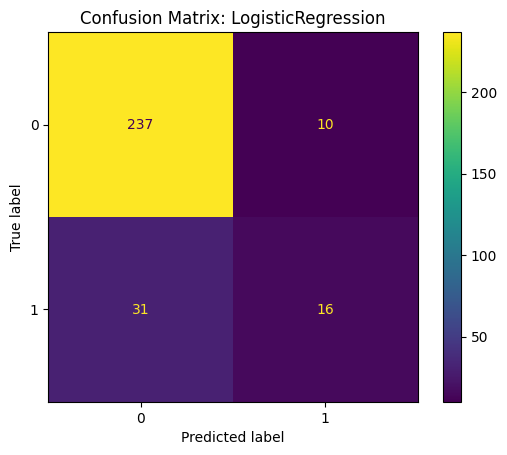


RandomForest Metrics:
 accuracy: 0.8469
precision: 0.6000
   recall: 0.1277
       f1: 0.2105
  roc_auc: 0.8057


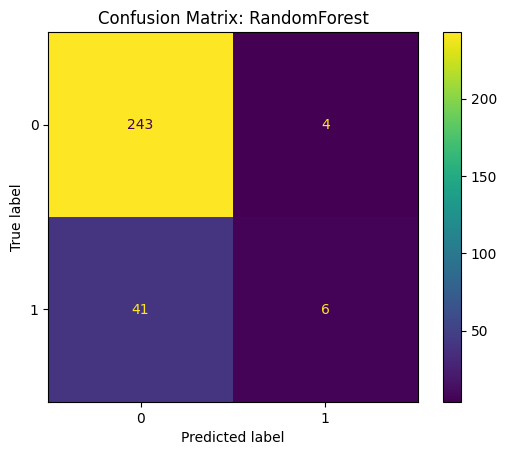

In [37]:
# function to standardize model evaluation
def evaluate(model_name, preds, proba, y_te):

    # calc accuracy metrics
    metrics = {
        'accuracy': accuracy_score(y_te, preds),
        'precision': precision_score(y_te, preds, zero_division=0),
        'recall': recall_score(y_te, preds, zero_division=0),
        'f1': f1_score(y_te, preds, zero_division=0),
        'roc_auc': roc_auc_score(y_te, proba) if proba is not None else np.nan
    }

    # print results
    print(f"\n{model_name} Metrics:")
    for k, v in metrics.items():
        print(f"{k:>9}: {v:.4f}")
    
    # display confusion matrix
    ConfusionMatrixDisplay.from_predictions(y_te, preds)
    plt.title(f'Confusion Matrix: {model_name}')
    plt.show()

    return metrics

# logistic regression model
log_reg = Pipeline(steps=[('prep', preprocessor),
                          ('clf', LogisticRegression(max_iter=200, n_jobs=None))])

log_reg.fit(X_train, y_train)
y_pred_log = log_reg.predict(X_test)
proba_log = log_reg.predict_proba(X_test)[:, 1] if hasattr(log_reg, 'predict_proba') else None

# random forest model
rf_clf = Pipeline(steps=[('prep', preprocessor),
                         ('clf', RandomForestClassifier(n_estimators=300, random_state=42))])

rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
proba_rf = rf_clf.predict_proba(X_test)[:, 1] if hasattr(rf_clf, 'predict_proba') else None


# compare evaluations and confusions matrices
results = {}
results['LogisticRegression'] = evaluate('LogisticRegression', y_pred_log, proba_log, y_test)
results['RandomForest'] = evaluate('RandomForest', y_pred_rf, proba_rf, y_test)

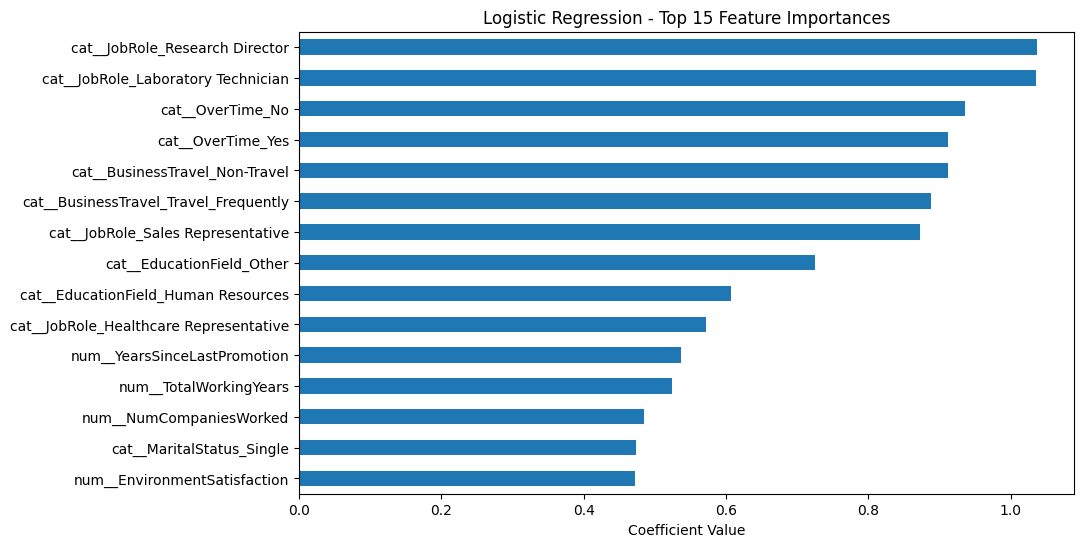

In [47]:
#### FEATURE IMPORTANCE ####
# feature importances
feature_names = preprocessor.get_feature_names_out(X.columns)
all_features = np.concatenate([feature_names, numeric_cols])
log_importances = pd.Series(abs(log_reg.named_steps['clf'].coef_[0]), index=feature_names)
log_importances = log_importances.sort_values(key=abs, ascending=False)

plt.figure(figsize=(10,6))
log_importances[:15].plot(kind="barh")
plt.title("Logistic Regression - Top 15 Feature Importances")
plt.xlabel("Coefficient Value")
plt.gca().invert_yaxis()
plt.show()

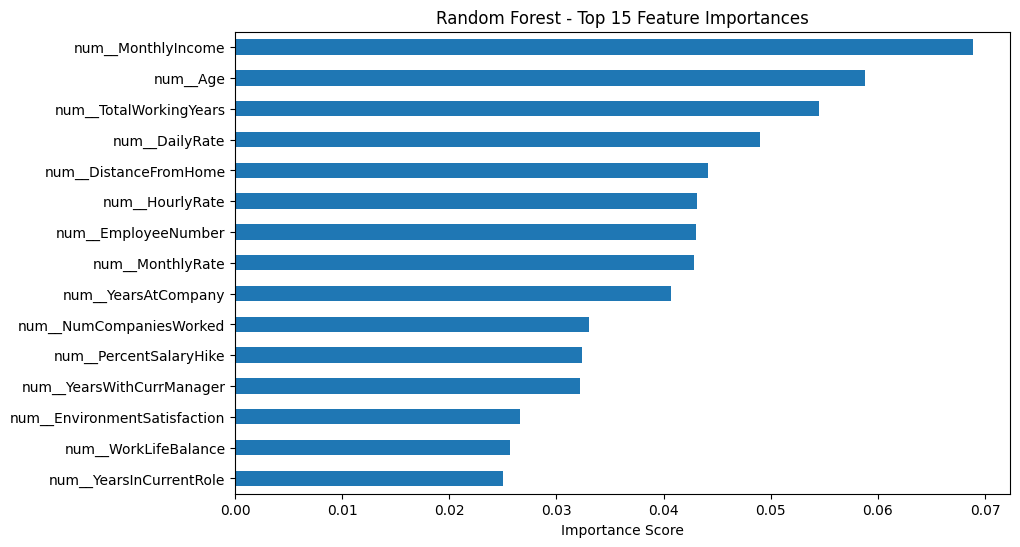

In [46]:
rf_importances = pd.Series(rf_clf.named_steps['clf'].feature_importances_, index=feature_names)
rf_importances = rf_importances.sort_values(ascending=False)

plt.figure(figsize=(10,6))
rf_importances[:15].plot(kind="barh")
plt.title("Random Forest - Top 15 Feature Importances")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.show()

### 5. Conclusion
---
*(Briefly describe what you have done and what you discovered. Discuss any shortcomings of the process and results. Propose future work. **Finally, discuss the lessons learned from doing the project**.)*

In [50]:
print('In conclusion, we created a Random Forest and  Logistic Regression model in order to predict employees who are risk of attrition.\n' \
'According to the ROC-AUC score, Logistic Regression was the best model. We also looked at the most important features in each model to \n' \
'understand what key risk factors influence attrition. Companies can use this prediction model to identify which of their employees are at risk.\n' \
'They can also use the most import features to target potential problem areas and improve retention. Things that can be done to improve this product\n' \
'would be to explore other models outside of Logistic Regression and Random Forest and to differentiate between termination and resignation.\n' \
'It is most likely that different factors influence termination and resignation, so this could improve the prediction model, assist the company with how\n' \
'to handle an employee at risk, and differntiate between risk factors for termination and risk factors for resignation. From this project\n' \
'I learned a lot about building machine learning models in Python. I have done this previously in R, so it was interesting transferring this\n' \
'knowledge to Python.')

In conclusion, we created a Random Forest and  Logistic Regression model in order to predict employees who are risk of attrition.
According to the ROC-AUC score, Logistic Regression was the best model. We also looked at the most important features in each model to 
understand what key risk factors influence attrition. Companies can use this prediction model to identify which of their employees are at risk.
They can also use the most import features to target potential problem areas and improve retention. Things that can be done to improve this product
would be to explore other models outside of Logistic Regression and Random Forest and to differentiate between termination and resignation.
It is most likely that different factors influence termination and resignation, so this could improve the prediction model, assist the company with how
to handle an employee at risk, and differntiate between risk factors for termination and risk factors for resignation. From this project
I learned a l

### 6. References

[Kaggle Dataset](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/data)

---
# Use the following requirements for preparing your project:

## DO NOT DELETE THE CELLS BELLOW

# Project Requirements

This final project examines the level of knowledge the students have learned from the course. The following course outcomes will be checked against the content of the report:

Upon successful completion of this course, a student will be able to:
* observe and explore a variety of quantitative methods for data analysis;
* understand methods’ evaluation techniques to interpret their output;
* implement and evaluate methods to gain technical experience with data; and
* reproducibly execute an analytic project and represent/communicate its results faithfully.

** Marking will be foucsed on both presentation and content.**

## Written Presentation Requirements
The report will be judged on the basis of visual appearance, grammatical correctness, and quality of writing, as well as its contents. Please make sure that the text of your report is well-structured, using paragraphs, full sentences, and other features of well-written presentation.

## Technical Content:
* Is the problem well defined and described thoroughly?
* Is the size and complexity of the data set used in this project comparable to that of the example data sets used in the lectures and assignments?
* Did the report describe the charactriatics of the data?
* Did the report describe the goals of the data analysis?
* Did the analysis conduct exploratory analyses on the data?
* Did the analysis build analysis models of the data and evaluated the performance of the models?
* Overall, what is the rating of this project?